In [1]:
import sys                              # sys: thông tin về chương trình Python đang chạy
from importlib.metadata import version  # hàm hỏi phiên bản của một thư viện đã cài

print(sys.executable)                   # in đường dẫn file python.exe đang chạy notebook
print("scanpy", version("scanpy"))      # in phiên bản Scanpy

C:\Users\ADMIN\miniconda3\envs\blastoid\python.exe
scanpy 1.11.5


In [2]:
# --- Imports -------------------------------------------------------------
import gc                            # gc = garbage collector; lets us free RAM on demand
import numpy as np                   # NumPy: fast numerical arrays ("np" is the usual alias)
import pandas as pd                  # pandas: tables / DataFrames ("pd" is the usual alias)
import scanpy as sc                  # Scanpy: single-cell analysis toolkit ("sc" is the usual alias)
import matplotlib.pyplot as plt      # matplotlib: plotting ("plt" is the usual alias)
from pathlib import Path             # Path: safe handling of file and folder paths

# --- Paths ---------------------------------------------------------------
project_dir = Path.cwd().parent                 # notebook lives in Notebook/, so its parent is the project root
raw_dir  = project_dir / "data" / "raw"         # extracted GEO files (large, not uploaded to GitHub)
proc_dir = project_dir / "data" / "processed"   # intermediate .h5ad files (large, not uploaded to GitHub)
fig_dir  = project_dir / "Figure"               # figures are saved here

# Stop early with a clear message if the folder layout is not what we expect
assert raw_dir.exists(), f"Cannot find {raw_dir}. Is this notebook inside the Notebook/ folder?"
proc_dir.mkdir(parents=True, exist_ok=True)     # create the folder if it is missing; no error if it exists
fig_dir.mkdir(parents=True, exist_ok=True)

# --- Samples -------------------------------------------------------------
# Dictionary: sample label -> file-name prefix of its three GEO files
samples = {
    "D7":  "GSM7083828_day7_blastoid",
    "D14": "GSM7083829_day14_blastoid",
    "D21": "GSM7677371",                         # label still to be verified on the GEO page of this GSM
}
print("Setup OK:", project_dir)

Setup OK: C:\Users\ADMIN\Documents\human-blastoid-scrna


In [3]:
def load_10x(prefix):
    """Read one 10x sample (matrix + features + barcodes) into an AnnData object (cells x genes)."""
    # The .mtx file stores genes x cells; .T (transpose) turns it into cells x genes, which Scanpy expects
    a = sc.read_mtx(raw_dir / f"{prefix}_matrix.mtx.gz").T
    # Tab-separated tables without a header row: column 0 = Ensembl ID, column 1 = gene symbol
    feat = pd.read_csv(raw_dir / f"{prefix}_features.tsv.gz", sep="\t", header=None)
    bc   = pd.read_csv(raw_dir / f"{prefix}_barcodes.tsv.gz", sep="\t", header=None)
    a.var_names = feat[1].values                  # gene symbols become the column names
    a.var["gene_id"] = feat[0].values             # keep the Ensembl IDs for later look-ups
    a.obs_names = bc[0].values                    # cell barcodes become the row names
    a.var_names_make_unique()                     # if two genes share a symbol, append -1, -2 to avoid errors
    # Total UMI counts per barcode = sum across all genes (axis=1 means "along each row")
    a.obs["total_counts"] = np.asarray(a.X.sum(axis=1)).ravel()
    return a


def barcode_rank_plot(a, label):
    """Print how many barcodes pass several UMI thresholds, then save a barcode rank plot."""
    print(label, "cells x genes =", a.shape)
    tc = a.obs["total_counts"].to_numpy()         # plain NumPy array of total UMI per barcode
    for t in [100, 500, 1000, 2000, 5000]:        # candidate thresholds to compare
        # (tc >= t) is a True/False array; .sum() counts the True values
        print(f"total_counts >= {t:>5}: {(tc >= t).sum():>9,} barcodes")
    ranked = np.sort(tc)[::-1]                    # sort ascending, then reverse -> largest barcode gets rank 1
    plt.figure(figsize=(6, 4.5))
    # log-log axes; np.clip raises zeros to 1 because log(0) is undefined
    plt.loglog(np.arange(1, len(ranked) + 1), np.clip(ranked, 1, None))
    plt.xlabel("Barcode rank")
    plt.ylabel("Total UMI counts")
    plt.title(f"{label} barcode rank plot")
    plt.savefig(fig_dir / f"{label}_barcode_rank.png", dpi=200, bbox_inches="tight")  # overwrites an existing file
    plt.show()


def call_cells(a, label, min_umi):
    """Keep barcodes with total UMI >= min_umi and save them as data/processed/<label>_cells.h5ad."""
    if min_umi is None:                           # safety guard: forces you to choose a threshold yourself
        raise ValueError("Set a threshold first, based on the barcode rank plot.")
    keep = a.obs["total_counts"] >= min_umi       # True for barcodes that are large enough to be cells
    cells = a[keep].copy()                        # .copy() makes an independent object so the big one can be freed
    cells.obs["timepoint"] = label                # record which sample each cell came from
    cells.write_h5ad(proc_dir / f"{label}_cells.h5ad")
    print(f"{label}: kept {cells.n_obs:,} of {a.n_obs:,} barcodes (min_umi = {min_umi})")

D7 cells x genes = (2194584, 36601)
total_counts >=   100:    86,669 barcodes
total_counts >=   500:     8,595 barcodes
total_counts >=  1000:     5,977 barcodes
total_counts >=  2000:     5,200 barcodes
total_counts >=  5000:     4,723 barcodes


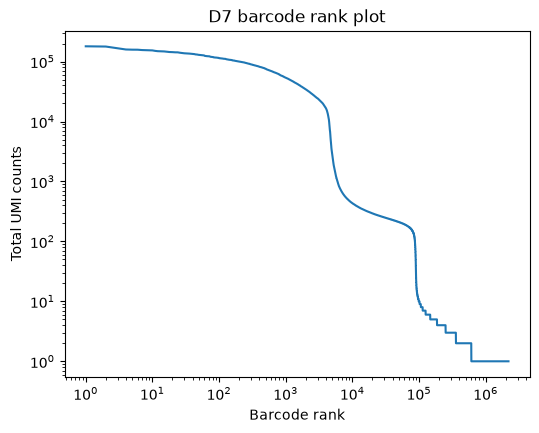

D7: kept 5,977 of 2,194,584 barcodes (min_umi = 1000)


16671

In [4]:
a = load_10x(samples["D7"])               # read the full raw matrix (about 2.2 million barcodes)
barcode_rank_plot(a, "D7")                # table + rank plot, to document the choice of threshold
call_cells(a, "D7", min_umi=1000)         # threshold 1000 chosen above the ambient-RNA plateau
del a                                     # remove the big object from memory
gc.collect()                              # ask Python to release the memory now

D14 cells x genes = (2667960, 36601)
total_counts >=   100:    82,350 barcodes
total_counts >=   500:    81,381 barcodes
total_counts >=  1000:    59,066 barcodes
total_counts >=  2000:     7,227 barcodes
total_counts >=  5000:     3,996 barcodes


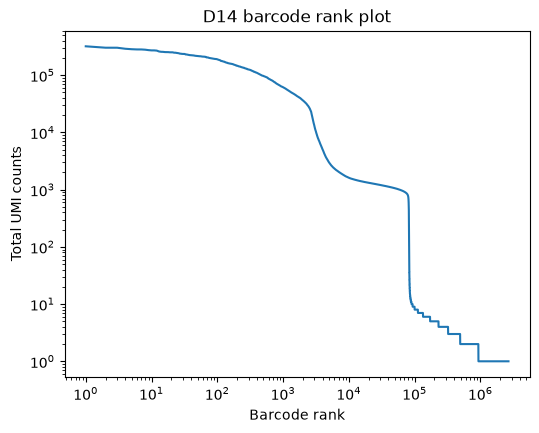

In [5]:
a = load_10x(samples["D14"])              # read the D14 raw matrix (about 2.7 million barcodes)
barcode_rank_plot(a, "D14")               # look for the steep drop and the ambient plateau, as for D7

total_counts >=   2000:   7,227 barcodes
total_counts >=   2500:   5,665 barcodes
total_counts >=   3000:   4,982 barcodes
total_counts >=   4000:   4,340 barcodes
total_counts >=   5000:   3,996 barcodes
total_counts >=   7500:   3,461 barcodes
total_counts >=  10000:   3,185 barcodes


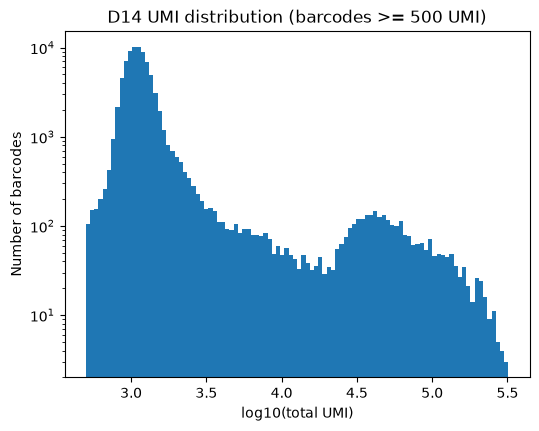

total_counts
[2000.0, 3000.0)     2245
[3000.0, 5000.0)      986
[5000.0, 10000.0)     811
[10000.0, inf)       3185
Name: count, dtype: int64
                   n_genes_by_counts  pct_counts_mt
total_counts                                       
[2000.0, 3000.0)              1003.0       7.977992
[3000.0, 5000.0)              1338.0       7.863982
[5000.0, 10000.0)             2146.0      22.828489
[10000.0, inf)                6436.0       7.423705


In [6]:
# --- 1. Finer thresholds around the shoulder between ambient plateau and real cells ---
tc = a.obs["total_counts"].to_numpy()                 # total UMI per barcode as a NumPy array
for t in [2000, 2500, 3000, 4000, 5000, 7500, 10000]:
    print(f"total_counts >= {t:>6}: {(tc >= t).sum():>7,} barcodes")

# --- 2. Histogram of log10(UMI) for barcodes with >= 500 UMI ---
# A valley between two peaks (ambient plateau vs real cells) suggests where to put the threshold
vals = np.log10(tc[tc >= 500])                        # log10 spreads out the wide range of UMI values
plt.figure(figsize=(6, 4.5))
plt.hist(vals, bins=100)                              # count barcodes in 100 bins along log10(UMI)
plt.yscale("log")                                     # log y-axis keeps the small "cell" group visible next to the huge plateau
plt.xlabel("log10(total UMI)")
plt.ylabel("Number of barcodes")
plt.title("D14 UMI distribution (barcodes >= 500 UMI)")
plt.savefig(fig_dir / "D14_umi_histogram.png", dpi=200, bbox_inches="tight")
plt.show()

# --- 3. Compare gene counts and mitochondrial fraction across UMI bands ---
sub = a[a.obs["total_counts"] >= 2000].copy()         # about 7,000 barcodes only, so this is cheap
sub.var["mt"] = sub.var_names.str.startswith("MT-")   # True for mitochondrial genes (symbols starting with "MT-")
sc.pp.calculate_qc_metrics(sub, qc_vars=["mt"], inplace=True)  # adds n_genes_by_counts and pct_counts_mt to sub.obs
bands = pd.cut(sub.obs["total_counts"],               # group barcodes into UMI bands: [2000,3000), [3000,5000), ...
               bins=[2000, 3000, 5000, 10000, np.inf], right=False)
print(bands.value_counts().sort_index())              # number of barcodes in each band
print(sub.obs.groupby(bands, observed=True)[["n_genes_by_counts", "pct_counts_mt"]].median())  # median per band

In [7]:
THRESH_D14 = 5000                          # inclusive cell calling: above the ambient plateau, keeps the intermediate group
call_cells(a, "D14", min_umi=THRESH_D14)   # keep barcodes with >= 5,000 UMI and save D14_cells.h5ad
del a                                      # remove the large raw object from memory
gc.collect()                               # ask Python to release the memory now

D14: kept 3,996 of 2,667,960 barcodes (min_umi = 5000)


115

D21 cells x genes = (6833, 36601)
total_counts >=   100:     6,833 barcodes
total_counts >=   500:     6,833 barcodes
total_counts >=  1000:     6,515 barcodes
total_counts >=  2000:     6,049 barcodes
total_counts >=  5000:     5,496 barcodes


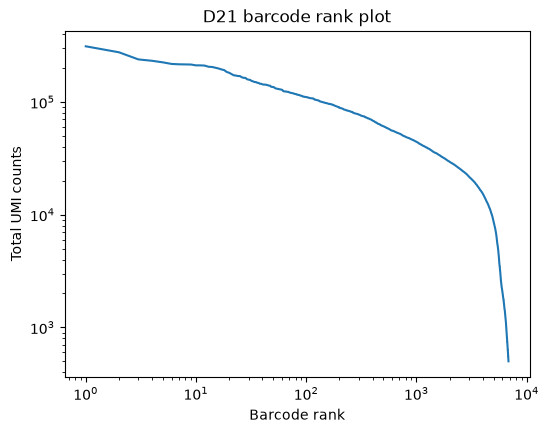

count      6833.000000
mean      24922.097656
std       25818.244141
min         500.000000
25%        7925.000000
50%       19032.000000
75%       32501.000000
max      312289.000000
Name: total_counts, dtype: float64


In [9]:
a = load_10x(samples["D21"])              # read the D21 matrix (6,833 barcodes expected)
barcode_rank_plot(a, "D21")               # threshold table + rank plot, as for D7 and D14
print(a.obs["total_counts"].describe())   # count, mean, min, quartiles and max of UMI per barcode

In [10]:
call_cells(a, "D21", min_umi=0)    # 0 keeps every barcode: the matrix is already filtered (minimum is 500 UMI)
del a                              # remove the object from memory
gc.collect()                       # ask Python to release the memory now

D21: kept 6,833 of 6,833 barcodes (min_umi = 0)


20897

In [11]:
for f in sorted(proc_dir.glob("*_cells.h5ad")):          # find every saved cell-called file
    print(f"{f.name:20s} {f.stat().st_size / 1024**2:8.1f} MB")

D14_cells.h5ad          172.8 MB
D21_cells.h5ad          200.5 MB
D7_cells.h5ad           185.3 MB
